# 01 · Experiment Validation and Exploration — Hillstrom E-Mail

**Context:** the *MineThatData E-Mail Analytics Challenge* dataset (Kevin Hillstrom, 2008) has 64,000 customers who made a purchase in the last twelve months. Each customer was randomly assigned to one of three groups: received an email featuring **men's** products, an email featuring **women's** products, or **no email** (control). Over the following two weeks, it was recorded whether the customer visited the site (`visit`), made a purchase (`conversion`), and how much they spent (`spend`).

**Objective of this notebook:** before estimating the effect of the campaigns, check that the experiment was properly run and understand the data. An A/B test only allows causal conclusions if the assignment was truly random, and this can be verified.

**Questions this notebook answers**
1. Is the data complete and consistent?
2. Do the three groups have the expected size (one third each)?
3. Are the groups comparable on pre-experiment characteristics?
4. How do the outcome variables (visit, conversion, and spend) behave?

## Analysis Plan

It is set before looking at the results, so as not to choose metrics or comparisons based on what "comes out well":

- **Main comparisons:** men's email vs. control, and women's email vs. control. **Secondary comparison:** men's email vs. women's email.
- **Primary metric:** conversion (whether the customer made a purchase). It is binary and directly measures the campaign's goal.
- **Secondary metrics:** site visit and spend per customer. Spend is the measure of business value, but it has a highly skewed distribution and is therefore analyzed with more care.
- **Statistical criterion:** significance level of 0.05 (two-sided), with correction for multiple comparisons (Holm, within each metric and across the three comparisons) and reporting of confidence intervals alongside p-values.
- **Segment analysis:** exploratory. It serves to generate hypotheses, not to confirm them.

## 1. Setup

The libraries and the data-loading functions from `src/data.py` are imported. The notebook assumes the repository structure (the `notebooks/` and `src/` folders inside the same root folder), which is why the parent folder is added to `sys.path`.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import load_hillstrom, prepare, GRUPOS

plt.rcParams["figure.dpi"] = 110

## 2. Data loading

`load_hillstrom()` reads the CSV from `data/raw/` or downloads it from the MineThatData blog the first time. `prepare()` validates that the expected columns are present and adds the `group` column with short names: `control`, `hombres`, and `mujeres`.

In [2]:
raw = load_hillstrom()
df = prepare(raw)
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (64000, 13)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,group
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0,women
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,control
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0,women
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,men
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0,women


## 3. Data Quality

The data types, null values, and variable ranges are reviewed, and the binary indicators are checked to contain only 0 and 1. Since the dataset has no customer identifier, duplicates cannot be verified: two identical rows may be different customers with the same characteristics.

In [3]:
print("Total null values:", int(df.isna().sum().sum()))
print()
print(df.dtypes)

Total null values: 0

recency               int64
history_segment         str
history             float64
mens                  int64
womens                int64
zip_code                str
newbie                int64
channel                 str
segment                 str
visit                 int64
conversion            int64
spend               float64
group              category
dtype: object


In [4]:
binarias = ["mens", "womens", "newbie", "visit", "conversion"]
for c in binarias:
    valores = sorted(df[c].unique().tolist())
    assert set(valores) <= {0, 1}, f"{c} has values outside 0/1: {valores}"
print("The binary variables contain only 0 and 1.")
print()
df[["recency", "history", "spend"]].describe().round(2)

The binary variables contain only 0 and 1.



,recency,history,spend
count,64000.00,64000.00,64000.00
mean,5.76,242.09,1.05
std,3.51,256.16,15.04
min,1.00,29.99,0.00
25%,2.00,64.66,0.00
50%,6.00,158.11,0.00
75%,9.00,325.66,0.00
max,12.00,3345.93,499.00


### 3.1 Consistency across outcome variables

Visiting the site, purchasing, and spending are related: there should be no spend without a purchase, and a purchase without a prior visit would be an unusual case. The original challenge explicitly asks to flag anomalies, so these cases are counted.

In [5]:
inconsistencias = pd.Series({
    "purchase without visit (conversion=1, visit=0)": int(((df.conversion == 1) & (df.visit == 0)).sum()),
    "spend without purchase(spend>0, conversion=0)": int(((df.spend > 0) & (df.conversion == 0)).sum()),
    "purchase without spend (conversion=1, spend=0)": int(((df.conversion == 1) & (df.spend == 0)).sum()),
})
inconsistencias.to_frame("filas")

,filas
"purchase without visit (conversion=1, visit=0)",0
"spend without purchase(spend>0, conversion=0)",0
"purchase without spend (conversion=1, spend=0)",0


## 4. Randomization Validation

### 4.1 Group size (Sample Ratio Mismatch)

If the assignment was 1/3 to each group, the observed sizes should be close to one third of the total. A large deviation (*sample ratio mismatch*) would indicate a problem in the assignment or in how the data was recorded, and would make all conclusions suspect. It is compared using a chi-square goodness-of-fit test.

In [6]:
conteo = df["group"].value_counts().reindex(GRUPOS)
esperado = np.full(len(GRUPOS), len(df) / len(GRUPOS))
chi2, p_srm = stats.chisquare(conteo.values, esperado)

tabla = pd.DataFrame({
    "customers": conteo,
    "proportion": conteo / len(df),
    "expected": esperado.round(1),
})
print(f"Chi-square = {chi2:.3f} | p = {p_srm:.4f}")
tabla.round(4)

Chi-square = 0.203 | p = 0.9037


,customers,proportion,expected
group,,,
control,21306,0.3329,21333.3
men,21307,0.3329,21333.3
women,21387,0.3342,21333.3


### 4.2 Balance of pre-experiment characteristics

If the assignment was random, the characteristics measured **before** the experiment (recency, purchase history, zone, channel, etc.) should be similarly distributed across the three groups. This is evaluated with hypothesis tests (chi-square for categorical variables, ANOVA and Kruskal-Wallis for numerical ones) and with the **standardized mean difference** (SMD) relative to the control, which does not depend on sample size. A common rule is to consider an SMD greater than 0.1 as problematic.

With several tests at once, it is expected that some will give p < 0.05 by chance alone: with 8 variables evaluated and no real difference, the probability that at least one turns out "significant" is approximately 34%.

In [7]:
categoricas = ["history_segment", "zip_code", "channel", "newbie", "mens", "womens"]
filas = []
for c in categoricas:
    tab = pd.crosstab(df["group"], df[c])
    chi2, p, gl, _ = stats.chi2_contingency(tab)
    n = tab.values.sum()
    v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
    filas.append({"feature": c, "test": "chi-square", "statistic": chi2, "p_value": p, "effect_size": v})

for c in ["recency", "history"]:
    groups = [df.loc[df.group == g, c] for g in GRUPOS]
    f, p_a = stats.f_oneway(*groups)
    h, p_k = stats.kruskal(*groups)
    filas.append({"feature": c, "test": "chi-square", "statistic": chi2, "p_value": p, "effect_size": np.nan})
    filas.append({"feature": c, "test": "chi-square", "statistic": chi2, "p_value": p, "effect_size": np.nan})

balance = pd.DataFrame(filas)
print("effect_size = Cramér's V (only for chi-square)")
balance.round(4)

effect_size = Cramér's V (only for chi-square)


,feature,test,statistic,p_value,effect_size
0,history_segment,chi-square,13.1533,0.3580,0.0101
1,zip_code,chi-square,2.8719,0.5795,0.0047
2,channel,chi-square,3.6324,0.4580,0.0053
3,newbie,chi-square,0.1369,0.9339,0.0015
4,mens,chi-square,0.7960,0.6717,0.0035
5,womens,chi-square,0.6325,0.7289,0.0031
6,recency,chi-square,0.6325,0.7289,NaN
7,recency,chi-square,0.6325,0.7289,NaN
8,history,chi-square,0.6325,0.7289,NaN
9,history,chi-square,0.6325,0.7289,NaN


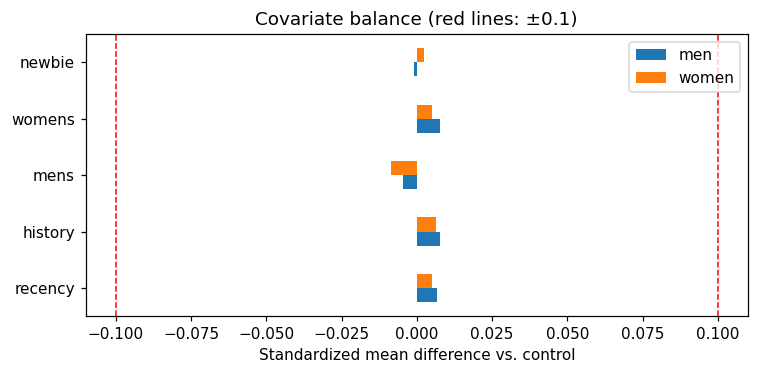

,men,women
recency,0.0068,0.0052
history,0.0076,0.0065
mens,-0.0046,-0.0086
womens,0.0076,0.0049
newbie,-0.0009,0.0026


In [8]:
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

vars_smd = ["recency", "history", "mens", "womens", "newbie"]
control = df[df.group == "control"]
smd_tab = pd.DataFrame({
    g: [smd(df.loc[df.group == g, c], control[c]) for c in vars_smd]
    for g in ["men", "women"]
}, index=vars_smd)

ax = smd_tab.plot.barh(figsize=(7, 3.5))
ax.axvline(0.1, color="red", linestyle="--", linewidth=1)
ax.axvline(-0.1, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Standardized mean difference vs. control")
ax.set_title("Covariate balance (red lines: ±0.1)")
plt.tight_layout()
plt.show()

smd_tab.round(4)

## 5. Outcome variables (description, no inference yet)

The three outcome variables are described. This section does **not** estimate or test the effect of the campaigns: that is done in notebook 02, with the confidence intervals and corrections from the analysis plan.

In [9]:
resumen = df.groupby("group", observed=True).agg(
    clientes=("visit", "size"),
    tasa_visita=("visit", "mean"),
    tasa_conversion=("conversion", "mean"),
    gasto_medio=("spend", "mean"),
)
resumen.round(4)

,clientes,tasa_visita,tasa_conversion,gasto_medio
group,,,,
control,21306,0.1062,0.0057,0.6528
men,21307,0.1828,0.0125,1.4226
women,21387,0.1514,0.0088,1.0772


### 5.1 Spend: many zeros and a long tail

Because conversion is infrequent, the vast majority of customers have zero spend, and among those who purchased there are few very high amounts. This distribution (skewed and with an excess of zeros) affects the choice of methods in notebook 02: with many zeros and a long tail, normality-based intervals may not be reliable, so they are compared against a bootstrap.

Customers with zero spend: 99.1%
Customers with positive spend: 578

Spend among those who spent:
count    578.00
mean     116.36
std      107.87
min       29.99
50%       80.80
90%      256.49
99%      499.00
max      499.00
Name: spend, dtype: float64


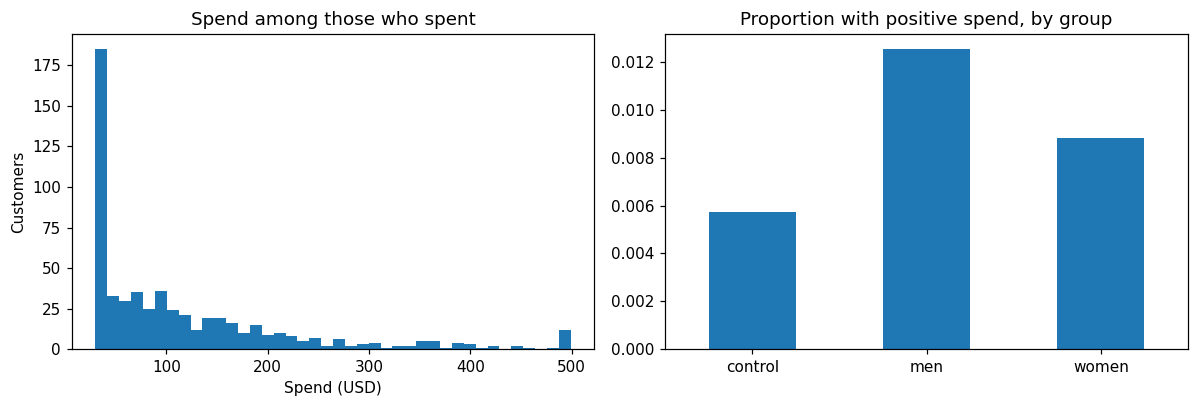

In [10]:
pct_cero = (df["spend"] == 0).mean()
compradores = df[df["spend"] > 0]["spend"]
print(f"Customers with zero spend: {pct_cero:.1%}")
print(f"Customers with positive spend: {len(compradores):,}")
print()
print("Spend among those who spent:")
print(compradores.describe(percentiles=[0.5, 0.9, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(compradores, bins=40)
axes[0].set_title("Spend among those who spent")
axes[0].set_xlabel("Spend (USD)")
axes[0].set_ylabel("Customers")

(df["spend"] > 0).groupby(df["group"], observed=True).mean().plot.bar(ax=axes[1])
axes[1].set_title("Proportion with positive spend, by group")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 6. Conclusions

- **Data quality:** 64,000 customers and 13 columns (the 12 original ones plus `grupo`), with no null values and with the binary variables containing only 0 and 1. There are no inconsistencies among the outcome variables: there is no spend without a purchase, no purchase without spend, and no purchase without a visit.
- **Group size:** 21,306 customers in control, 21,307 with the men's email, and 21,387 with the women's email. The chi-square test (p = 0.90) detects no deviation from one third per group, so there is no sample ratio mismatch.
- **Balance of pre-experiment characteristics:** the p-values of the 10 tests range from 0.36 to 0.93, Cramér's V is 0.010 or lower, and the maximum standardized mean difference is 0.009 (the alert threshold is 0.1). There is no evidence of imbalance, which is consistent with correct randomization and allows later differences to be attributed to the email. A high p-value does not prove that the groups are identical, only that no difference is detected.
- **Outcome variables (description):** the visit rate is 10.6% in control, 18.3% with the men's email, and 15.1% with the women's; conversion is 0.57%, 1.25%, and 0.88%; and mean spend per customer is 0.65, 1.42, and 1.08 dollars. These differences are formally evaluated in notebook 02.
- **Spend distribution:** 99.1% of customers spent nothing and only 578 (0.9%) made a purchase. Among them, the mean is 116.36 dollars and the median 80.80, so the distribution is right-skewed. The 99th percentile and the maximum coincide at 499.00, which suggests that several customers have exactly that amount and could reflect a cap in how the data was recorded (not verified). Notebook 02 checks that the result does not depend on the high amounts.
- **Implications for the analysis:** conversion is a rare event (0.9%), which limits the power to detect small differences, and spend, because of its zeros and long tail, is also analyzed with methods that do not assume normality, such as the bootstrap.
- **Limitations:** there is no customer identifier, so duplicates could not be verified; follow-up covers only two weeks; the experiment includes only customers who purchased in the last 12 months, so the results do not extend to new or inactive customers; and there is no campaign cost data.
- **Next step:** notebook 02 estimates the effect of each campaign on conversion, visit, and spend, with confidence intervals and correction for multiple comparisons.